# 11. SVM Regressor

**Project** · Concrete Compressive Strength Prediction  
**Problem type** · Regression

This dataset is synthetic and designed for education. Keep its predictions within the exercise. Any real-world financial, medical, safety, educational or employment decision requires independent evidence and validation.

Start with Sections 1–9 for your first model. Then try parameter tuning and the interview exercises. Run the code cells in order because each step uses results from earlier cells.

## 1. Introduction

Support vector regression fits a function with an error tolerance around its predictions. Errors inside the tolerance contribute zero training loss. A kernel lets the fitted function model a curved relationship such as strength gained during curing.

By the end, you can implement the pipeline, explain how it predicts and use holdout results to identify where it struggles.

## 2. Understand the Dataset

A weighted cement, fly ash and slag total divided by water gives a binder ratio. Strength grows with that ratio and curing age with diminishing returns. Superplasticizer adds a small term, aggregate deviations reduce strength, and Gaussian noise of 3.4 MPa is added before flooring.

| Column | Type | Units or values | Meaning |
| --- | --- | --- | --- |
| `cement_kg_m3` | decimal | kg/m³ | Cement mass per cubic metre of mix |
| `water_kg_m3` | decimal | kg/m³ | Mix water mass per cubic metre |
| `fly_ash_kg_m3` | decimal | kg/m³ | Fly ash content per cubic metre |
| `blast_furnace_slag_kg_m3` | decimal | kg/m³ | Slag content per cubic metre |
| `aggregates_kg_m3` | decimal | kg/m³ | Combined aggregate content per cubic metre |
| `superplasticizer_kg_m3` | decimal | kg/m³ | Superplasticizer per cubic metre |
| `curing_age_days` | integer | days | Age at compressive testing |
| `compressive_strength_mpa` | decimal | MPa | Observed continuous outcome |

**Independent variables (X)** · `cement_kg_m3`, `water_kg_m3`, `fly_ash_kg_m3`, `blast_furnace_slag_kg_m3`, `aggregates_kg_m3`, `superplasticizer_kg_m3`, `curing_age_days`.

**Dependent variable (y)** · `compressive_strength_mpa` is the continuous quantity to predict in MPa. The preview shows the first 10 rows, dimensions and stored types. Blank features, where present, are intentional.

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import display

csv_name = "11_concrete_strength.csv"
csv_path = Path("../datasets") / csv_name

# Also look in the project folder or the location used for Colab uploads.
if not csv_path.is_file():
    csv_path = Path("datasets") / csv_name
if not csv_path.is_file():
    csv_path = Path("Machine_Learning_Complete_Guide/datasets") / csv_name
if not csv_path.is_file():
    csv_path = Path(csv_name)

df = pd.read_csv(csv_path, keep_default_na=False, na_values=[""])
print("Dataset shape:", df.shape)
display(df.head(10))
display(df.dtypes)

Dataset shape: (1500, 8)


,cement_kg_m3,water_kg_m3,fly_ash_kg_m3,blast_furnace_slag_kg_m3,aggregates_kg_m3,superplasticizer_kg_m3,curing_age_days,compressive_strength_mpa
0,257.2,153.1,69.6,145.8,1869.5,4.86,7,24.43
1,210.3,152.9,72.1,78.4,1688.0,7.59,14,33.84
2,392.1,211.4,4.3,36.8,1637.9,8.79,56,39.99
3,394.6,219.3,4.8,103.2,1508.9,3.86,28,29.36
4,370.2,180.1,15.4,90.7,1865.0,17.90,28,45.48
5,196.0,209.9,142.9,6.5,1816.4,10.03,28,29.17
6,252.3,172.0,23.5,38.1,1545.8,6.32,28,31.88
7,405.0,215.3,138.2,64.3,1755.2,7.54,7,18.97
8,332.9,202.3,99.8,129.1,1828.9,15.93,56,49.34
9,437.5,220.4,67.2,149.2,1753.6,15.41,56,54.45


cement_kg_m3                float64
water_kg_m3                 float64
fly_ash_kg_m3               float64
blast_furnace_slag_kg_m3    float64
aggregates_kg_m3            float64
superplasticizer_kg_m3      float64
curing_age_days               int64
compressive_strength_mpa    float64
dtype: object

## 3. Mathematical Understanding

The epsilon-insensitive loss is $L_\epsilon(y,f(x))=\max(0,|y-f(x)|-\epsilon)$. Here $y$ is measured strength, $x$ is the mix profile, $f(x)$ is predicted strength, and $\epsilon$ is the half-width of the tolerance tube. Fit by trading the function’s complexity $\lVert w\rVert^2/2$ in feature space against $C\sum_i L_\epsilon(y_i,f(x_i))$, with $C$ controlling the loss penalty.

At $\epsilon=2$ MPa and prediction $35$ MPa, observations $34$, $37$ and $40$ MPa have losses $0$, $0$ and $3$ MPa. Rows on or outside the tube can have nonzero coefficients and become support vectors. The RBF kernel weighs similarity according to squared standardized distance, with $\gamma$ controlling its spatial reach.

[scikit-learn user guide](https://scikit-learn.org/stable/modules/svm.html#regression)

## 4. Working Principle

Fit an imputer and scaler on training mixes, then place a smooth function through the data with a tolerance tube around it. Rows strictly inside the tube need no loss penalty. The learned support vectors determine the curve used for new mixes.

| Observed strength | Absolute error | Loss |
| --- | --- | --- |
| 34 MPa | 1 MPa | 0 MPa |
| 37 MPa | 2 MPa | 0 MPa |
| 40 MPa | 5 MPa | 3 MPa |

**Workflow diagram**

`Raw input` → `Standardized numeric values and any category indicators` → `Fits a regularized function with an epsilon-insensitive loss` → `Estimate in MPa`.

## 5. Dataset Exploration

The first and last rows verify parsing. Shape and info reveal size, stored types and non-missing counts. Summary statistics show typical values, ranges and spread. Missingness and duplicate counts identify possible cleanup needs. The target plot shows the range and shape of the outcome. Feature plots show variation. Pearson correlation measures linear association. Watch for nonlinear trends even if a linear association is present. The features and evaluation design are fixed before modeling.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
TARGET = "compressive_strength_mpa"
FEATURES = ["cement_kg_m3","water_kg_m3","fly_ash_kg_m3","blast_furnace_slag_kg_m3","aggregates_kg_m3","superplasticizer_kg_m3","curing_age_days"]
NUMERIC = ["cement_kg_m3","water_kg_m3","fly_ash_kg_m3","blast_furnace_slag_kg_m3","aggregates_kg_m3","superplasticizer_kg_m3","curing_age_days"]
CATEGORICAL = []
SEED = 42

In [3]:
df.info()
display(df.head())
display(df.tail())
display(df.describe(include="all").T)
display(pd.DataFrame({"Missing": df.isna().sum(), "Missing %": 100 * df.isna().mean()}).round(1))
print("Exact duplicate rows:", df.duplicated().sum())
print("Repeated feature rows:", df.duplicated(subset=FEATURES).sum())

<class 'pandas.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 8 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   cement_kg_m3              1500 non-null   float64
 1   water_kg_m3               1500 non-null   float64
 2   fly_ash_kg_m3             1470 non-null   float64
 3   blast_furnace_slag_kg_m3  1500 non-null   float64
 4   aggregates_kg_m3          1500 non-null   float64
 5   superplasticizer_kg_m3    1500 non-null   float64
 6   curing_age_days           1500 non-null   int64  
 7   compressive_strength_mpa  1500 non-null   float64
dtypes: float64(7), int64(1)
memory usage: 93.9 KB


,cement_kg_m3,water_kg_m3,fly_ash_kg_m3,blast_furnace_slag_kg_m3,aggregates_kg_m3,superplasticizer_kg_m3,curing_age_days,compressive_strength_mpa
0,257.2,153.1,69.6,145.8,1869.5,4.86,7,24.43
1,210.3,152.9,72.1,78.4,1688.0,7.59,14,33.84
2,392.1,211.4,4.3,36.8,1637.9,8.79,56,39.99
3,394.6,219.3,4.8,103.2,1508.9,3.86,28,29.36
4,370.2,180.1,15.4,90.7,1865.0,17.90,28,45.48


,cement_kg_m3,water_kg_m3,fly_ash_kg_m3,blast_furnace_slag_kg_m3,aggregates_kg_m3,superplasticizer_kg_m3,curing_age_days,compressive_strength_mpa
1495,170.9,189.6,133.5,170.2,1735.1,8.05,3,9.57
1496,211.2,201.7,35.0,116.9,1516.9,15.18,28,37.73
1497,471.3,155.1,37.9,92.3,1527.4,14.96,90,57.16
1498,464.5,170.6,136.2,72.4,1827.6,17.60,28,48.60
1499,299.6,216.1,105.7,17.0,1595.6,13.04,28,32.95


,count,mean,std,min,25%,50%,75%,max
cement_kg_m3,1500.0,318.338733,92.305627,150.30,239.450,321.100,398.1000,474.50
water_kg_m3,1500.0,185.553067,28.918275,135.10,160.600,185.600,210.3250,234.80
fly_ash_kg_m3,1470.0,71.597551,41.296004,0.10,36.425,71.250,107.8750,144.90
blast_furnace_slag_kg_m3,1500.0,88.957000,51.298774,0.00,43.700,90.700,134.2250,174.90
aggregates_kg_m3,1500.0,1713.337067,123.162754,1500.00,1609.700,1715.800,1820.3250,1929.90
superplasticizer_kg_m3,1500.0,8.806953,5.180544,0.00,4.285,8.785,13.1125,18.00
curing_age_days,1500.0,31.725333,25.716975,3.00,14.000,28.000,56.0000,90.00
compressive_strength_mpa,1500.0,33.980620,12.240380,5.45,24.800,34.110,42.1775,71.25


,Missing,Missing %
cement_kg_m3,0,0.0
water_kg_m3,0,0.0
fly_ash_kg_m3,30,2.0
blast_furnace_slag_kg_m3,0,0.0
aggregates_kg_m3,0,0.0
superplasticizer_kg_m3,0,0.0
curing_age_days,0,0.0
compressive_strength_mpa,0,0.0


Exact duplicate rows: 0
Repeated feature rows: 0


### Plot the target

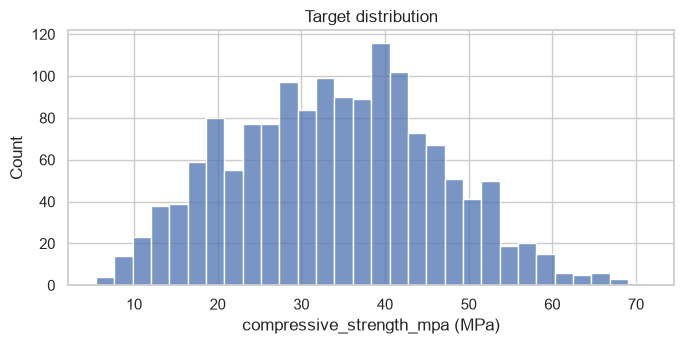

In [4]:
fig, ax = plt.subplots(figsize=(7, 3.6))
sns.histplot(data=df, x=TARGET, bins=30, ax=ax)
ax.set_xlabel("compressive_strength_mpa (MPa)")
ax.set_title("Target distribution")
fig.tight_layout()
plt.show()

### Look at the input features

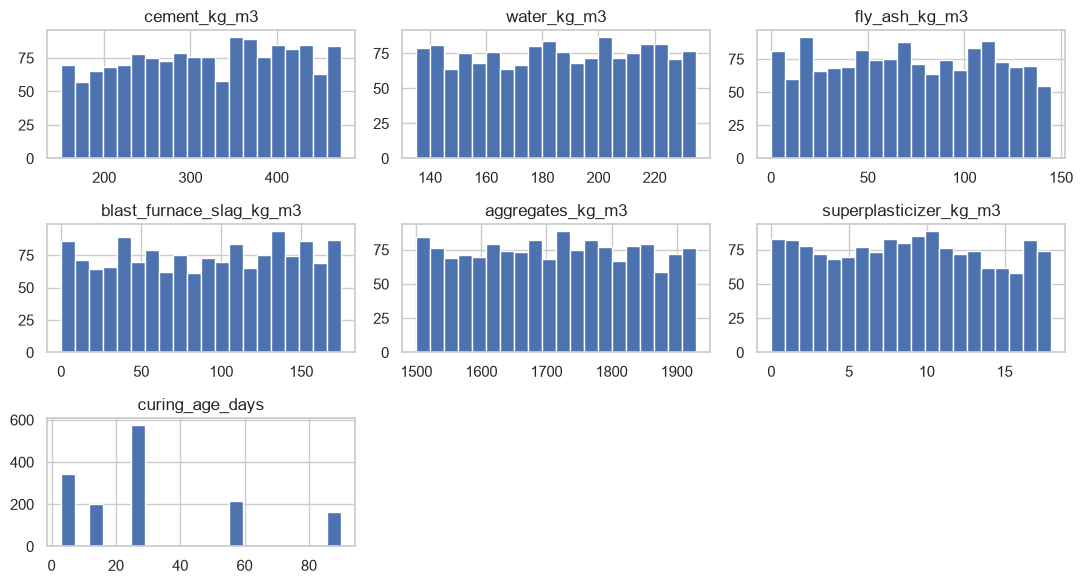

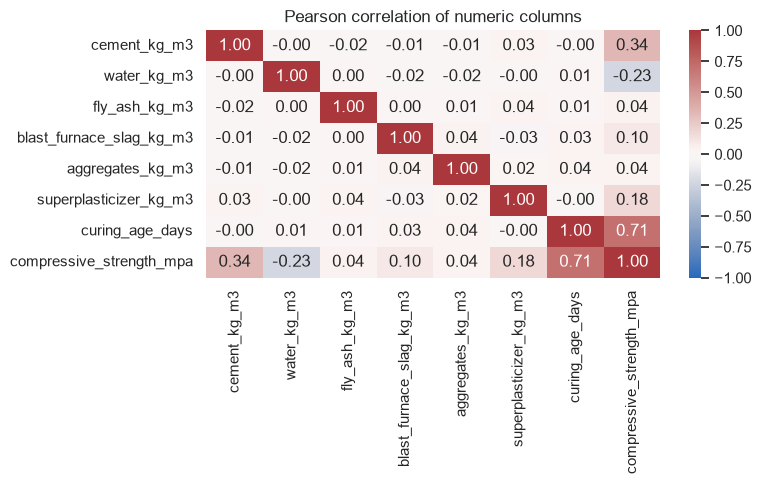

In [5]:
df[NUMERIC].hist(figsize=(11, 6), bins=20)
plt.tight_layout()
plt.show()

correlation_columns = NUMERIC + [TARGET]
fig, ax = plt.subplots(figsize=(8, 5))
sns.heatmap(df[correlation_columns].corr(), annot=True, fmt=".2f", cmap="vlag",
            center=0, vmin=-1, vmax=1, ax=ax)
ax.set_title("Pearson correlation of numeric columns")
fig.tight_layout()
plt.show()

## 6. Data Preprocessing

Select the input columns and target explicitly. A seeded random split suits these independently generated rows. The numeric branch fills blanks using training medians. This dataset has no categorical predictors. StandardScaler uses training means and standard deviations to make numeric magnitudes comparable. The pipeline fits each preprocessing step after the split and repeats it in each training fold.

Exact and feature-only duplicate counts are listed above. Identical measurements with distinct outcomes can represent legitimate observations.

### 1. Choose the inputs and target

In [6]:
# X contains the inputs. y contains the answer for each row.
X = df[FEATURES]
y = df[TARGET]

### 2. Split the rows into training and test sets

In [7]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED
)

print("Training rows:", len(X_train))
print("Test rows:", len(X_test))

Training rows: 1200
Test rows: 300


### 3. Prepare the columns

The next cell sets up the cleaning steps. They learn their values later, when you fit the model.

In [8]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# Fill blank numbers, then put numeric columns on comparable scales.
numeric_preprocess = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("scale", StandardScaler()),
])

preprocess = ColumnTransformer(
    [
        ("numeric", numeric_preprocess, NUMERIC),
    ],
    verbose_feature_names_out=False,
)

## 7. Model Implementation

`C` balances smoothness and errors outside the tube, `epsilon` is measured in MPa because only predictors are scaled, and `gamma` controls locality for the RBF kernel. A linear kernel assumes an additive straight relationship in transformed features.

- The estimator import provides the algorithm implementation.
- `Pipeline` joins preprocessing and the model in execution order.
- `fit(X_train, y_train)` learns transformations and parameters from training rows.
- `predict(...)` applies the fitted steps to new rows. The first holdout row gives a preview before scoring the entire split.

### Create the model

In [9]:
from sklearn.svm import SVR

estimator = SVR(C=25, epsilon=1.5, kernel="rbf", gamma="scale")
model = Pipeline([
    ("preprocess", preprocess),
    ("model", estimator),
])

### Fit on the training rows

In [10]:
# Learn from the training rows.
model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocess', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](7,)","['cement_kg_m3','water_kg_m3','fly_ash_kg_m3',...,'aggregates_kg_m3', 'superplasticizer_kg_m3','curing_age_days']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,7
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...)]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will n

### Predict on the test rows

In [11]:
# Predict using the held-out inputs.
predictions = model.predict(X_test)
display(X_test.head(1))
print(f"Example prediction: {predictions[0]:,.2f} MPa")

,cement_kg_m3,water_kg_m3,fly_ash_kg_m3,blast_furnace_slag_kg_m3,aggregates_kg_m3,superplasticizer_kg_m3,curing_age_days
1116,398.6,175.5,115.5,110.4,1636.4,13.89,28


Example prediction: 46.86 MPa


## 8. Model Evaluation

Let $y_i$ be the actual test value for row $i$, $\hat y_i$ its prediction, $e_i=y_i-\hat y_i$ its residual, $n$ the number of test rows and $\bar y$ the test target mean.

| Metric | Formula | Interpretation |
| --- | --- | --- |
| Mean absolute error | $\mathrm{MAE}=n^{-1}\sum_i\lvert e_i\rvert$ | Mean absolute miss in the target unit. Lower is better. |
| Mean squared error | $\mathrm{MSE}=n^{-1}\sum_i e_i^2$ | Mean squared miss in squared units. It puts more weight on large errors. Lower is better. |
| Root mean squared error | $\mathrm{RMSE}=\sqrt{\mathrm{MSE}}$ | Error on the target scale that emphasizes large misses. Lower is better. |
| Coefficient of determination | $R^2=1-\sum_i e_i^2/\sum_i(y_i-\bar y)^2$ | Higher is better. One is a perfect fit, zero matches the squared error of the test mean, and negative means more error than that reference. |

The baseline predicts the **training** target mean, so its test R² may be slightly negative. Compare MAE and RMSE to it in the table below.

**Target unit** · MPa.

In [12]:
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, root_mean_squared_error, r2_score

initial_metrics = {
    "MAE": mean_absolute_error(y_test, predictions),
    "MSE": mean_squared_error(y_test, predictions),
    "RMSE": root_mean_squared_error(y_test, predictions),
    "R²": r2_score(y_test, predictions),
}
display(pd.Series(initial_metrics, name="Test score").round(3))

MAE      3.331
MSE     17.590
RMSE     4.194
R²       0.875
Name: Test score, dtype: float64

### Compare with a simple baseline

In [13]:
# A baseline predicts the mean training target for every row.
baseline = DummyRegressor(strategy="mean")
baseline.fit(X_train, y_train)
baseline_predictions = baseline.predict(X_test)

baseline_metrics = {
    "MAE": mean_absolute_error(y_test, baseline_predictions),
    "MSE": mean_squared_error(y_test, baseline_predictions),
    "RMSE": root_mean_squared_error(y_test, baseline_predictions),
    "R²": r2_score(y_test, baseline_predictions),
}
display(pd.DataFrame([baseline_metrics, initial_metrics], index=["Baseline", "Model"]).round(3))

,MAE,MSE,RMSE,R²
Baseline,9.551,141.26,11.885,-0.002
Model,3.331,17.59,4.194,0.875


## 9. Visualizations

Compare estimated and measured outcomes against the 45-degree line. A point above that line is an overestimate. In the residual panel, points above zero are underestimates. A systematic curve suggests missing structure, and widening scatter suggests changing error spread.

The shaded band shows training residuals no larger than epsilon. The marked support vectors are the training rows retained in the SVR decision function. The held-out diagnostics above measure predictive errors separately.

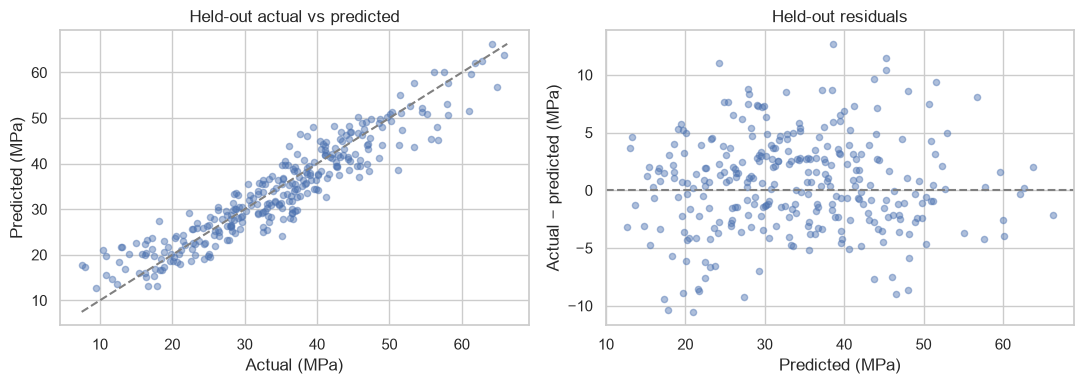

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
limits = [min(y_test.min(), predictions.min()), max(y_test.max(), predictions.max())]
axes[0].scatter(y_test, predictions, s=20, alpha=0.45)
axes[0].plot(limits, limits, color="grey", linestyle="--")
axes[0].set(xlabel="Actual (MPa)", ylabel="Predicted (MPa)", title="Held-out actual vs predicted")
axes[1].scatter(predictions, y_test - predictions, s=20, alpha=0.45)
axes[1].axhline(0, color="grey", linestyle="--")
axes[1].set(xlabel="Predicted (MPa)", ylabel="Actual − predicted (MPa)", title="Held-out residuals")
fig.tight_layout()
plt.show()

### A closer look at this model

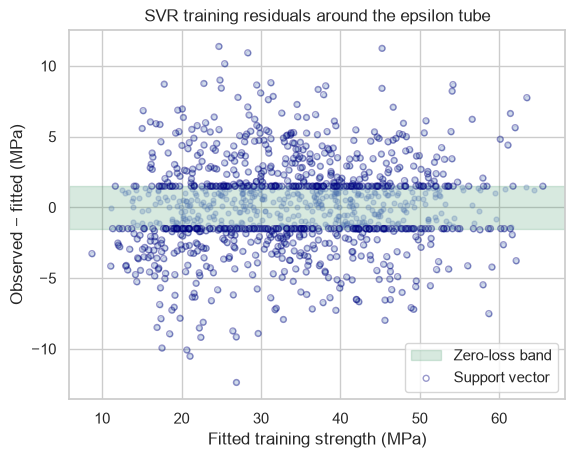

In [15]:
svr = model.named_steps["model"]
fitted = model.predict(X_train)
residuals = (y_train - fitted).to_numpy()
fig, ax = plt.subplots()
ax.axhspan(-svr.epsilon, svr.epsilon, color="seagreen", alpha=0.19, label="Zero-loss band")
ax.scatter(fitted, residuals, s=12, alpha=0.25)
ax.scatter(fitted[svr.support_], residuals[svr.support_], facecolors="none", edgecolors="navy",
           s=18, alpha=0.4, label="Support vector")
ax.set(xlabel="Fitted training strength (MPa)", ylabel="Observed − fitted (MPa)", title="SVR training residuals around the epsilon tube")
ax.legend()
plt.show()

## 10. Hyperparameter Tuning

GridSearchCV tries the grid with three shuffled folds within the training data. Each candidate gets a freshly fitted pipeline per fold. Rank by lowest RMSE. The scorer negates RMSE so that the best score ranks first. `refit=True` fits the winner on all training rows. Use the CV ranks to choose parameters and the holdout to report performance.

`C` balances smoothness and errors outside the tube, `epsilon` is measured in MPa because only predictors are scaled, and `gamma` controls locality for the RBF kernel. A linear kernel assumes an additive straight relationship in transformed features.

[GridSearchCV documentation](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html)

### Set up the candidate settings

In [16]:
from sklearn.model_selection import GridSearchCV, KFold

param_grid = [{"model__kernel": ["linear"], "model__C": [3, 25], "model__epsilon": [0.5, 2]},
 {"model__kernel": ["rbf"], "model__C": [3, 25], "model__epsilon": [0.5, 2],
  "model__gamma": ["scale", 0.08]}]
validation = KFold(n_splits=3, shuffle=True, random_state=SEED)
search = GridSearchCV(model, param_grid, scoring="neg_root_mean_squared_error", cv=validation,
                      refit=True, n_jobs=1, error_score="raise")

### Search using training rows

In [17]:
search.fit(X_train, y_train)
tuned_model = search.best_estimator_
results = pd.DataFrame(search.cv_results_).sort_values("rank_test_score")
results["Mean fold RMSE"] = -results["mean_test_score"]
print("Best training-CV parameters:", search.best_params_)
display(results[["rank_test_score", "Mean fold RMSE", "std_test_score", "params"]].head().round(3))

Best training-CV parameters: {'model__C': 25, 'model__epsilon': 2, 'model__gamma': 0.08, 'model__kernel': 'rbf'}


,rank_test_score,Mean fold RMSE,std_test_score,params
11,1,4.293,0.026,"{'model__C': 25, 'model__epsilon': 2, 'model__..."
9,2,4.298,0.040,"{'model__C': 25, 'model__epsilon': 0.5, 'model..."
10,3,4.383,0.045,"{'model__C': 25, 'model__epsilon': 2, 'model__..."
8,4,4.411,0.061,"{'model__C': 25, 'model__epsilon': 0.5, 'model..."
5,5,4.959,0.036,"{'model__C': 3, 'model__epsilon': 0.5, 'model_..."


### Compare the models on the test set

In [18]:
tuned_predictions = tuned_model.predict(X_test)

tuned_metrics = {
    "MAE": mean_absolute_error(y_test, tuned_predictions),
    "MSE": mean_squared_error(y_test, tuned_predictions),
    "RMSE": root_mean_squared_error(y_test, tuned_predictions),
    "R²": r2_score(y_test, tuned_predictions),
}
comparison = pd.DataFrame(
    [baseline_metrics, initial_metrics, tuned_metrics],
    index=["Baseline", "First model", "Tuned model"],
)
display(comparison.round(3))

,MAE,MSE,RMSE,R²
Baseline,9.551,141.26,11.885,-0.002
First model,3.331,17.59,4.194,0.875
Tuned model,3.357,17.75,4.213,0.874


## 11. Real-World Prediction

Pass three new examples to the CV-selected pipeline. Read the estimates in MPa and compare the scenarios to see how the fitted model responds.

### Enter three new examples

In [19]:
examples = pd.DataFrame([
    [290, 177, 55, 70, 1710, 6, 7],
    [338, 164, 42, 82, 1730, 7.5, 28],
    [402, 158, 65, 90, 1760, 10, 56],
], columns=FEATURES)
display(examples)

,cement_kg_m3,water_kg_m3,fly_ash_kg_m3,blast_furnace_slag_kg_m3,aggregates_kg_m3,superplasticizer_kg_m3,curing_age_days
0,290,177,55,70,1710,6.0,7
1,338,164,42,82,1730,7.5,28
2,402,158,65,90,1760,10.0,56


### Make predictions

In [20]:
sample_inputs = examples
prediction_model = tuned_model
sample_predictions = prediction_model.predict(sample_inputs)
example_output = examples.copy()
example_output["Scenario"] = ["Seven-day mix","Twenty-eight-day mix","Long-cured mix with more binder"]
example_output["Predicted compressive_strength_mpa (MPa)"] = sample_predictions.round(2)
display(example_output)

,cement_kg_m3,water_kg_m3,fly_ash_kg_m3,blast_furnace_slag_kg_m3,aggregates_kg_m3,superplasticizer_kg_m3,curing_age_days,Scenario,Predicted compressive_strength_mpa (MPa)
0,290,177,55,70,1710,6.0,7,Seven-day mix,17.68
1,338,164,42,82,1730,7.5,28,Twenty-eight-day mix,41.22
2,402,158,65,90,1760,10.0,56,Long-cured mix with more binder,59.92


## 12. Limitations and Advantages

SVR can model smooth nonlinear trends while ignoring small errors. It depends on scaling, its fit can be costly on large datasets and the tube does not supply predictive intervals. Strong smoothing can underfit and high gamma with low epsilon can chase noise. Use for moderate-sized smooth problems and avoid unvalidated use on novel mix compositions.

## 13. Interview Preparation

### A. 30-second explanation

> I modeled synthetic concrete strength using support vector regression. The epsilon-insensitive loss ignores small deviations and penalizes only the excess outside a tolerance tube. I compared linear and RBF kernels, evaluated MPa errors and inspected where fitted training residuals fell relative to epsilon.

### B. 90-second technical explanation

> I modeled synthetic concrete strength using support vector regression. The epsilon-insensitive loss ignores small deviations and penalizes only the excess outside a tolerance tube. I compared linear and RBF kernels, evaluated MPa errors and inspected where fitted training residuals fell relative to epsilon. My target was compressive strength mpa, and the inputs were cement kg m3, water kg m3, fly ash kg m3, blast furnace slag kg m3, aggregates kg m3, superplasticizer kg m3, curing age days. Fit an imputer and scaler on training mixes, then place a smooth function through the data with a tolerance tube around it. Rows strictly inside the tube need no loss penalty. The learned support vectors determine the curve used for new mixes. I held out 20% of the rows and fitted preprocessing within each training fold. I measured MAE in MPa and RMSE to see how much larger errors mattered. I compared the model with a training-mean predictor and inspected residuals. The inputs and labels were generated for teaching, so the holdout performance describes this exercise. For real data I would confirm which inputs are available at prediction time and build a split that reflects where the model will be used.

### C. Ten technical questions

1. **What kind of target does SVR predict?** A continuous numeric value.
2. **What is epsilon-insensitive loss?** The absolute error in excess of epsilon, floored at zero.
3. **What happens as epsilon increases?** More residuals can fall inside the zero-loss tube.
4. **What does C control?** The cost of errors beyond the tube relative to model complexity.
5. **What are SVR support vectors?** Training rows with nonzero dual coefficients.
6. **What does gamma do?** It controls the decay of RBF similarity with distance.
7. **Why scale predictors but leave the target unscaled here?** It makes the kernel distances meaningful and keeps epsilon interpretable in MPa.
8. **Can a support vector lie exactly on the tube?** Yes. Boundary points may have nonzero coefficients.
9. **Is the tube a confidence interval?** No. It is a training-loss tolerance.
10. **How do you compare kernel choices?** Use cross-validation with scaling fitted in each fold.

### D. Five scenario questions

1. **Epsilon is 10 MPa and residuals show systematic curvature. What would you try?** Compare smaller epsilon and an RBF fit on training validation folds.
2. **One ingredient has a value near 1,900 while others are near 10. What helps?** Scale feature columns using training statistics.
3. **A novel blend lies outside the training ranges. What should you infer?** The output is extrapolated and needs representative physical measurements to validate it.
4. **You need prediction intervals. Is epsilon enough?** Use a method that estimates uncertainty and check interval coverage.
5. **Many mixes are measured at multiple ages. What split would you use?** Group by mix identity when evaluating transfer to new recipes.

### E. Three common mistakes

- Interpreting epsilon as a guaranteed tolerance. Inspect held-out errors.
- Reusing unscaled kernel settings after feature units change. Retune on training data.
- Selecting a kernel by training fit alone. Compare validation scores.

### F. Complete project explanation

Use the measured scores in a short project walkthrough. Start with the problem, explain the pipeline and close with what the evaluation can support. This cell inserts results from the current run.

In [21]:
from IPython.display import Markdown

summary = (
    "I built a supervised regression project for concrete compressive strength prediction using SVM Regressor. I generated 1,500 synthetic observations and used cement kg m3, water kg m3, fly ash kg m3, blast furnace slag kg m3, aggregates kg m3, superplasticizer kg m3, curing age days to predict compressive strength mpa. I used a holdout and a preprocessing pipeline fitted within training folds. I compared the selected estimator with a simple baseline. "
    f"On the holdout, the CV-selected model achieved MAE {tuned_metrics['MAE']:,.2f} MPa, "
    f"compared with {baseline_metrics['MAE']:,.2f} MPa for the training-mean baseline. "
    f"Its RMSE was {tuned_metrics['RMSE']:,.2f} MPa. "
    "I compared training residuals with the epsilon tube and located the support vectors. These results apply to the synthetic data and should be validated on representative observations before practical use."
)
display(Markdown("> " + summary))

> I built a supervised regression project for concrete compressive strength prediction using SVM Regressor. I generated 1,500 synthetic observations and used cement kg m3, water kg m3, fly ash kg m3, blast furnace slag kg m3, aggregates kg m3, superplasticizer kg m3, curing age days to predict compressive strength mpa. I used a holdout and a preprocessing pipeline fitted within training folds. I compared the selected estimator with a simple baseline. On the holdout, the CV-selected model achieved MAE 3.36 MPa, compared with 9.55 MPa for the training-mean baseline. Its RMSE was 4.21 MPa. I compared training residuals with the epsilon tube and located the support vectors. These results apply to the synthetic data and should be validated on representative observations before practical use.